# De la donnée à la décision — Statistiques pour les Experts Data

## TP 02 — Notions de probabilités utiles

**Auteur :** Bassem Ben Hamed — `bassem.benhamed@enetcom.usf.tn`

**Contenu :** Modules 4 et 5 de la formation (Partie 2 — Probabilités).

**Dataset fil rouge :** *Pharmaceutical Sales Data* (Kaggle / Milan Zdravković) — déjà utilisé en TP 01.

Ce notebook accompagne le module 02 Probabilités. La logique est la même qu'en TP 01 :
1. **Rappel théorique** (formule + intuition).
2. **Code commenté** en français.
3. **Interprétation business** systématique.

> Les formules sont rappelées dans le notebook même si elles figurent dans les slides — la répétition est volontaire pour fixer les notations.

## Sommaire

- **Setup** — imports, chargement du dataset
- **Module 4** — Le minimum vital pour un analyst
  - Vocabulaire et axiomes de Kolmogorov
  - Interprétation fréquentiste (loi des grands nombres)
  - Probabilité conditionnelle, indépendance
  - Théorème de Bayes — cas du test diagnostic
  - Variable aléatoire, PMF, PDF, CDF
  - Espérance et variance
  - Pont stat $\leftrightarrow$ proba
- **Module 5** — Lois de probabilité usuelles
  - Lois discrètes : Bernoulli, Binomiale, Poisson, Géométrique
  - Lois continues : Uniforme, Normale, Log-normale, Exponentielle
  - Lois des tests (Student, $\chi^2$, Fisher) — mention
  - Odds et odds ratio
  - `scipy.stats` : `pdf`, `cdf`, `ppf`, `rvs`
  - Cas pratique : ajustement empirique sur le dataset
- **Synthèse**

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

### Chargement du dataset

On reprend le dataset *Pharma Sales Data* du TP 01.

In [2]:
csv_path = Path('dataset') / 'salesdaily.csv'
df_raw = pd.read_csv(csv_path, parse_dates=['datum'], dayfirst=False)
df_raw = df_raw.rename(columns={'datum': 'date'}).set_index('date').sort_index()

categories = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
df = df_raw[categories].copy()

JOURS_FR = {0: 'lundi', 1: 'mardi', 2: 'mercredi', 3: 'jeudi',
            4: 'vendredi', 5: 'samedi', 6: 'dimanche'}

def saison(mois):
    return ('hiver' if mois in (12, 1, 2)
            else 'printemps' if mois in (3, 4, 5)
            else 'été' if mois in (6, 7, 8)
            else 'automne')

print(f'Forme : {df.shape}')
print(f'Période : {df.index.min().date()} -> {df.index.max().date()}')
df.head()

Forme : (2106, 8)
Période : 2014-01-02 -> 2019-10-08


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
date,,,,,,,,
2014-01-02,0.00,3.67,3.40,32.40,7.00,0.00,0.00,2.00
2014-01-03,8.00,4.00,4.40,50.60,16.00,0.00,20.00,4.00
2014-01-04,2.00,1.00,6.50,61.85,10.00,0.00,9.00,1.00
2014-01-05,4.00,3.00,7.00,41.10,8.00,0.00,3.00,0.00
2014-01-06,5.00,1.00,4.50,21.70,16.00,2.00,6.00,2.00


---
## Module 4 — Le minimum vital pour un analyst

Objectifs : acquérir le vocabulaire qui permet de lire correctement la suite (TCL, p-values, intervalles de confiance, régression logistique).

### 4.1 Vocabulaire de base

| Objet | Notation | Définition |
|---|---|---|
| Expérience aléatoire | — | Phénomène à issue incertaine |
| Univers | $\Omega$ | Ensemble de tous les résultats possibles |
| Événement | $A \subseteq \Omega$ | Sous-ensemble de l'univers |
| Probabilité | $\mathbb{P}(A) \in [0, 1]$ | Mesure de la « vraisemblance » de $A$ |

**Trois axiomes de Kolmogorov :**
1. $0 \leq \mathbb{P}(A) \leq 1$
2. $\mathbb{P}(\Omega) = 1$ (un résultat se produit forcément)
3. Si $A \cap B = \emptyset$ : $\mathbb{P}(A \cup B) = \mathbb{P}(A) + \mathbb{P}(B)$

**Sur notre dataset :** $\Omega$ = ensemble des jours observés. Un événement = sous-ensemble de jours (par ex. « le dimanche », « ventes N02BE > 50 »).

### 4.2 Interprétation fréquentiste — démonstration empirique

$$\mathbb{P}(A) = \lim_{n \to \infty} \frac{n_A}{n}$$

« La probabilité, c'est la fréquence relative à long terme. » Vérifions sur le dataset.

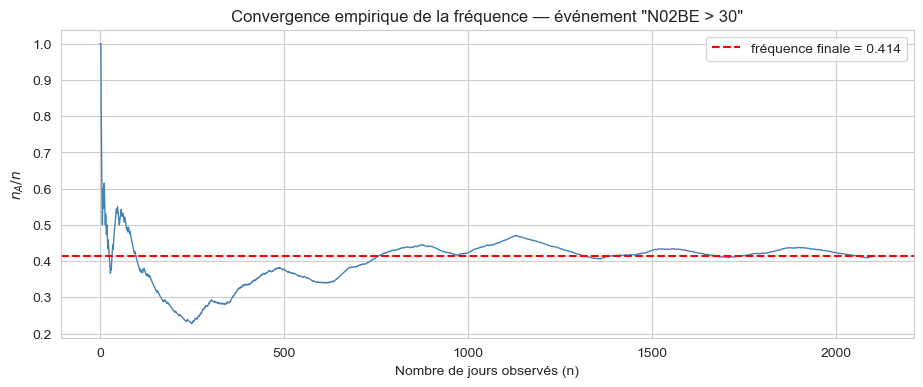

In [3]:
# Définition de l'événement A : « ventes N02BE supérieures à 30 »
A = df['N02BE'] > 30

# Fréquence relative cumulée au fil des jours
freq_cumulee = A.expanding().mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(freq_cumulee.values, color='steelblue', lw=1)
ax.axhline(A.mean(), color='red', ls='--', label=f'fréquence finale = {A.mean():.3f}')
ax.set_xlabel('Nombre de jours observés (n)')
ax.set_ylabel(r'$n_A / n$')
ax.set_title('Convergence empirique de la fréquence — événement "N02BE > 30"')
ax.legend(); plt.show()

**Lecture :** la fréquence relative oscille fortement aux premiers jours puis se stabilise. C'est la **loi des grands nombres** en action — $\bar{x}_n \to \mu$ quand $n \to \infty$. C'est exactement ce qui justifie d'estimer une probabilité inconnue par une fréquence observée.

### 4.3 Règles de calcul élémentaires

$$\mathbb{P}(\bar{A}) = 1 - \mathbb{P}(A)$$
$$\mathbb{P}(A \cup B) = \mathbb{P}(A) + \mathbb{P}(B) - \mathbb{P}(A \cap B)$$
$$\mathbb{P}(A \cap B) = \mathbb{P}(A) \cdot \mathbb{P}(B \mid A)$$

Vérifions la formule de l'union sur deux événements concrets.

In [4]:
A = df['N02BE'] > df['N02BE'].quantile(0.75)   # forte vente N02BE
B = df['M01AB'] > df['M01AB'].quantile(0.75)   # forte vente M01AB

p_A      = A.mean()
p_B      = B.mean()
p_AnB    = (A & B).mean()
p_AuB    = (A | B).mean()
p_AuB_th = p_A + p_B - p_AnB  # par la formule

print(f'P(A)         = {p_A:.3f}')
print(f'P(B)         = {p_B:.3f}')
print(f'P(A ∩ B)     = {p_AnB:.3f}')
print(f'P(A ∪ B) obs = {p_AuB:.3f}')
print(f'P(A ∪ B) théo= {p_AuB_th:.3f}  ← identique : la formule est vérifiée')

P(A)         = 0.250
P(B)         = 0.247
P(A ∩ B)     = 0.078
P(A ∪ B) obs = 0.419
P(A ∪ B) théo= 0.419  ← identique : la formule est vérifiée


### 4.4 Probabilité conditionnelle

$$\mathbb{P}(A \mid B) = \frac{\mathbb{P}(A \cap B)}{\mathbb{P}(B)}$$

« Probabilité de A *sachant que* B s'est produit. » On **réduit l'univers** à B.

In [5]:
# Question : sachant qu'on est un dimanche, quelle est la probabilité d'une forte vente N02BE ?
dimanche = df.index.dayofweek == 6
forte    = df['N02BE'] > df['N02BE'].quantile(0.75)

p_forte_global    = forte.mean()
p_forte_si_dim    = forte[dimanche].mean()           # P(forte | dimanche)
p_forte_si_semaine = forte[~dimanche].mean()         # P(forte | non-dimanche)

print(f'P(forte vente)             = {p_forte_global:.3f}')
print(f'P(forte vente | dimanche)  = {p_forte_si_dim:.3f}')
print(f'P(forte vente | semaine)   = {p_forte_si_semaine:.3f}')

P(forte vente)             = 0.250
P(forte vente | dimanche)  = 0.352
P(forte vente | semaine)   = 0.233


**Interprétation :** la probabilité d'une forte vente **chute fortement le dimanche** par rapport à un jour de semaine. La connaissance du jour change radicalement la probabilité — les deux événements ne sont donc *pas* indépendants.

### 4.5 Indépendance

$A$ et $B$ sont **indépendants** si :
$$\mathbb{P}(A \cap B) = \mathbb{P}(A) \cdot \mathbb{P}(B)$$

Ou encore : $\mathbb{P}(A \mid B) = \mathbb{P}(A)$ (la connaissance de B ne change rien).

Testons numériquement entre N02BE et M01AB.

In [6]:
A = df['N02BE'] > df['N02BE'].quantile(0.75)
B = df['M01AB'] > df['M01AB'].quantile(0.75)

ratio = (A & B).mean() / (A.mean() * B.mean())
print(f'P(A ∩ B)         = {(A & B).mean():.3f}')
print(f'P(A) × P(B)      = {(A.mean() * B.mean()):.3f}')
print(f'Ratio (= 1 si indépendants) : {ratio:.2f}')

P(A ∩ B)         = 0.078
P(A) × P(B)      = 0.062
Ratio (= 1 si indépendants) : 1.27


**Lecture :** le ratio est nettement supérieur à 1 $\Rightarrow$ N02BE et M01AB **ne sont pas indépendants** (les fortes ventes co-occurrent plus souvent qu'attendu sous indépendance). Cela confirme la corrélation positive vue en TP 01.

### 4.6 Théorème de Bayes — cas du test diagnostic

$$\mathbb{P}(A \mid B) = \frac{\mathbb{P}(B \mid A) \cdot \mathbb{P}(A)}{\mathbb{P}(B)}$$

**Cas pratique :** un test de dépistage avec
- Prévalence $\mathbb{P}(M) = 1\,\%$
- Sensibilité $\mathbb{P}(T^+ \mid M) = 99\,\%$
- Spécificité 95 % donc $\mathbb{P}(T^+ \mid \bar{M}) = 5\,\%$

Si le test est positif, quelle est la probabilité d'être malade ?

In [7]:
p_M       = 0.01    # prévalence
p_pos_M   = 0.99    # sensibilité
p_pos_nM  = 0.05    # 1 - spécificité
p_nM      = 1 - p_M

# Probabilité totale d'un test positif
p_pos = p_pos_M * p_M + p_pos_nM * p_nM

# Bayes
p_M_pos = p_pos_M * p_M / p_pos

print(f'P(test positif)              = {p_pos:.4f}')
print(f'P(malade | test positif)     = {p_M_pos:.4f}  -> seulement {p_M_pos*100:.1f} %')

P(test positif)              = 0.0594
P(malade | test positif)     = 0.1667  -> seulement 16.7 %


**Interprétation :** un test très précis sur une maladie rare donne **beaucoup de faux positifs**. C'est l'erreur classique en santé, en détection de fraude, ou en spam-filtering. Un patient positif n'a en réalité que ~17 % de chances d'être malade.

### 4.7 Variable aléatoire

Une **variable aléatoire** $X$ est une fonction qui associe un nombre à chaque résultat de l'expérience :
$$X : \Omega \longrightarrow \mathbb{R}$$

Chaque colonne du DataFrame est une **réalisation** d'une variable aléatoire. Par exemple, `df['R06']` contient 2106 réalisations de la variable aléatoire $X$ = « ventes journalières d'antihistaminiques ».

**Ce changement de point de vue est central :** en Partie 1 on regardait des chiffres ; ici on les voit comme des **réalisations** d'un mécanisme probabiliste sous-jacent.

### 4.8 Variables discrètes vs continues

| | Discrète | Continue |
|---|---|---|
| Valeurs | $\{0, 1, 2, \dots\}$ | tout intervalle de $\mathbb{R}$ |
| Loi | PMF $\mathbb{P}(X=k)$ | PDF $f(x)$ |
| Calcul de proba | somme | intégrale |
| Exemple pharma | nombre de jours sans vente N05C | volume vendu de N02BE (flottant) |

**Subtilité (continu) :** $\mathbb{P}(X = x_0) = 0$ pour toute valeur précise. Seuls les **intervalles** ont une probabilité non nulle :
$$\mathbb{P}(a \leq X \leq b) = \int_a^b f(x)\,\mathrm{d}x$$

### 4.9 Loi de probabilité — PMF, PDF, CDF

**PMF** (Probability Mass Function) — cas discret :
$$p_X(k) = \mathbb{P}(X = k), \quad p_X(k) \geq 0, \quad \sum_k p_X(k) = 1$$

**PDF** (Probability Density Function) — cas continu :
$$f_X(x) \geq 0, \quad \int_{-\infty}^{+\infty} f_X(x)\,\mathrm{d}x = 1$$

**CDF** (Cumulative Distribution Function) — discret ou continu :
$$F_X(x) = \mathbb{P}(X \leq x)$$

Toujours croissante de 0 à 1. La **réciproque** $F_X^{-1}(q)$ donne le **quantile** d'ordre $q$.

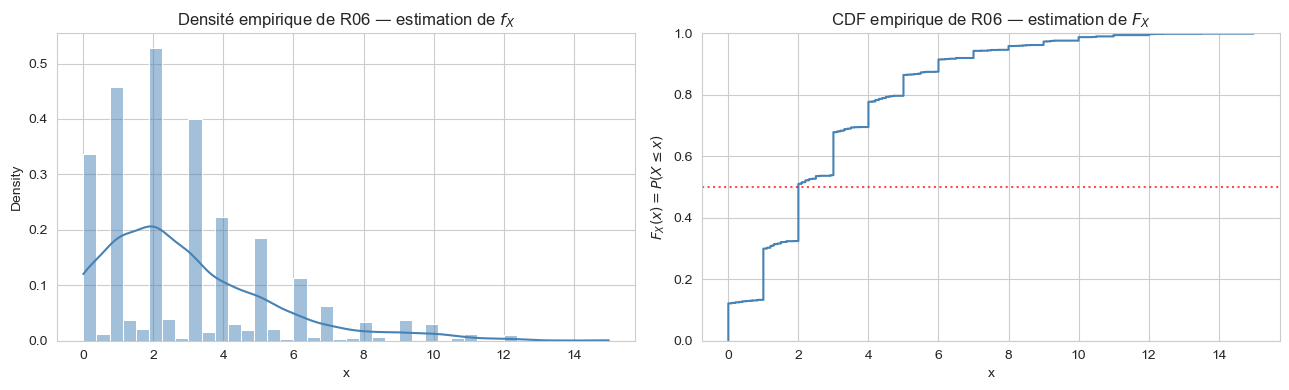

In [8]:
# Histogramme + ECDF empirique pour R06 (estimation de PDF et CDF)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# PDF empirique (densité)
sns.histplot(df['R06'], bins=40, stat='density', kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Densité empirique de R06 — estimation de $f_X$')
axes[0].set_xlabel('x')

# CDF empirique (ECDF)
sns.ecdfplot(df['R06'], ax=axes[1], color='steelblue')
axes[1].axhline(0.5, color='red', ls=':', alpha=0.7)
axes[1].set_title('CDF empirique de R06 — estimation de $F_X$')
axes[1].set_xlabel('x'); axes[1].set_ylabel(r'$F_X(x) = P(X \leq x)$')
plt.tight_layout(); plt.show()

**Lecture de la CDF :** la valeur 0,5 correspond à la médiane. Sur la courbe, on lit graphiquement la médiane (intersection avec $y = 0{,}5$). Toute probabilité du type $\mathbb{P}(X \leq 5)$ se lit directement.

### 4.10 Espérance et variance

**Espérance :**
$$\mathbb{E}[X] = \sum_k k\, \mathbb{P}(X = k) \quad \text{(discret)}, \qquad \mathbb{E}[X] = \int x\, f_X(x)\,\mathrm{d}x \quad \text{(continu)}$$

**Variance :**
$$\mathrm{Var}(X) = \mathbb{E}\!\left[(X - \mathbb{E}[X])^2\right] = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$$

**Loi des grands nombres :** quand $n \to \infty$, la moyenne empirique $\bar{x}_n$ converge vers $\mathbb{E}[X]$. C'est ce qui justifie qu'on **estime** $\mu$ par $\bar{x}$.

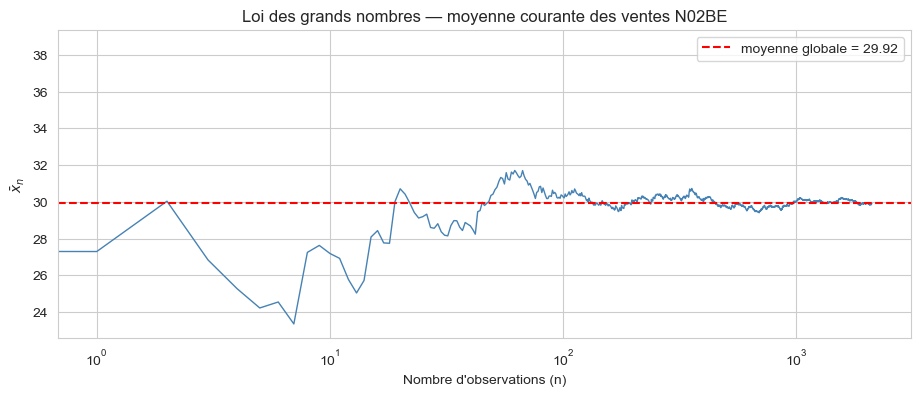

In [9]:
# Démonstration de la LGN sur N02BE
x = df['N02BE'].sample(frac=1, random_state=0).values  # mélange aléatoire de l'ordre
moyenne_courante = pd.Series(x).expanding().mean()
moyenne_finale   = x.mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(moyenne_courante, color='steelblue', lw=1)
ax.axhline(moyenne_finale, color='red', ls='--', label=f'moyenne globale = {moyenne_finale:.2f}')
ax.set_xlabel('Nombre d\'observations (n)')
ax.set_ylabel(r'$\bar{x}_n$')
ax.set_title('Loi des grands nombres — moyenne courante des ventes N02BE')
ax.set_xscale('log')
ax.legend(); plt.show()

**Interprétation :** plus on accumule d'observations, plus la moyenne empirique se stabilise autour de l'espérance théorique. Avec moins de 100 jours, la moyenne fluctue beaucoup ; au-delà de 1000 jours, elle est très proche de la valeur asymptotique. **C'est exactement pourquoi on a besoin d'échantillons « assez grands » pour estimer un KPI avec confiance.**

### 4.11 Pont statistique $\leftrightarrow$ probabilité

| | Statistique (M1) | Probabilité (M4) |
|---|---|---|
| | *ce qu'on observe* | *ce qui les a générés* |
| Centre | $\bar{x}$ | $\mathbb{E}[X] = \mu$ |
| Dispersion | $s$, $s^2$ | $\sigma$, $\sigma^2$ |
| Distribution | histogramme | PMF / PDF |
| Cumul | ECDF empirique | CDF $F_X$ |

**À retenir :** la statistique décrit ce qu'on a observé. La probabilité décrit ce qu'on s'attendrait à observer si on répétait l'expérience. L'**inférence** (Partie 3) est le pont entre les deux.

---
## Module 5 — Lois de probabilité usuelles

### 5.1 Loi de Bernoulli

$$\mathbb{P}(X = 1) = p, \quad \mathbb{P}(X = 0) = 1 - p$$
$$\mathbb{E}[X] = p, \qquad \mathrm{Var}(X) = p(1 - p)$$

Brique de base pour modéliser un essai binaire (clic / pas clic, succès / échec).

In [10]:
# Sur le dataset : événement « jour de forte vente N02BE » (au-dessus du 90e percentile)
seuil = df['N02BE'].quantile(0.90)
X = (df['N02BE'] > seuil).astype(int)   # 1 si forte vente, 0 sinon

p = X.mean()
var_emp = X.var(ddof=1)
var_th  = p * (1 - p)

print(f'Seuil (P90 N02BE) : {seuil:.2f}')
print(f'p estimé          : {p:.3f}')
print(f'E[X] = p          : {p:.3f}')
print(f'Var empirique     : {var_emp:.3f}')
print(f'Var théorique p(1-p) : {var_th:.3f}  ← identique')

Seuil (P90 N02BE) : 50.80
p estimé          : 0.100
E[X] = p          : 0.100
Var empirique     : 0.090
Var théorique p(1-p) : 0.090  ← identique


**Lecture :** la variance empirique colle parfaitement à $p(1-p)$, ce qui confirme que l'événement « forte vente » est bien Bernoulli($p$). C'est la **brique de base** que l'on va combiner pour la binomiale.

### 5.2 Loi binomiale $B(n, p)$

$$\mathbb{P}(X = k) = \binom{n}{k}\,p^k\,(1-p)^{n-k}, \quad k \in \{0, 1, \dots, n\}$$
$$\mathbb{E}[X] = np, \qquad \mathrm{Var}(X) = np(1-p)$$

Somme de $n$ Bernoullis indépendants.

E[X]   = n·p          = 2.99
σ(X)   = √[n·p·(1-p)] = 1.64


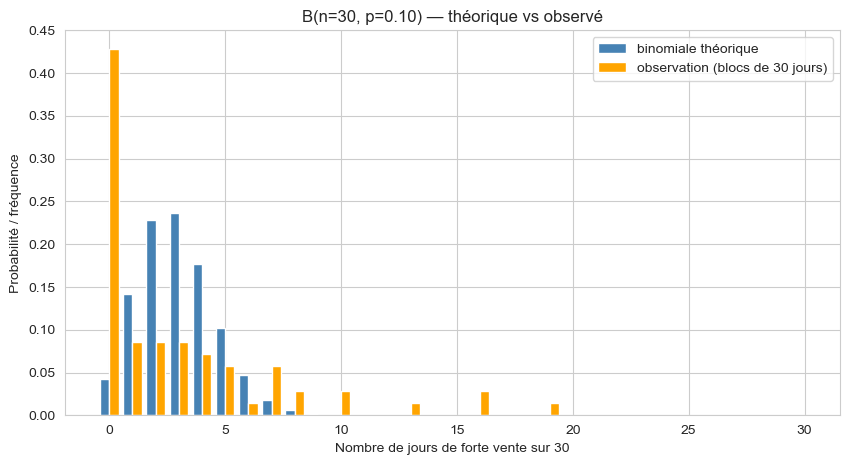

In [11]:
# Question : sur 30 jours consécutifs, combien de jours de "forte vente" attend-on ?
n_jours = 30
esperance = n_jours * p
ecart_type = np.sqrt(n_jours * p * (1 - p))
print(f'E[X]   = n·p          = {esperance:.2f}')
print(f'σ(X)   = √[n·p·(1-p)] = {ecart_type:.2f}')

# PMF théorique
k = np.arange(0, n_jours + 1)
pmf = stats.binom.pmf(k, n_jours, p)

# Comparaison avec l'observation : on découpe le dataset en blocs de 30 jours
blocs = X.values[:len(X) // n_jours * n_jours].reshape(-1, n_jours).sum(axis=1)

fig, ax = plt.subplots()
ax.bar(k - 0.2, pmf, width=0.4, label='binomiale théorique', color='steelblue')
obs_counts = pd.Series(blocs).value_counts(normalize=True).sort_index()
ax.bar(obs_counts.index + 0.2, obs_counts.values, width=0.4,
       label='observation (blocs de 30 jours)', color='orange')
ax.set_xlabel('Nombre de jours de forte vente sur 30')
ax.set_ylabel('Probabilité / fréquence')
ax.set_title(f'B(n={n_jours}, p={p:.2f}) — théorique vs observé')
ax.legend(); plt.show()

**Interprétation business :** sur 30 jours, on s'attend à ~3 jours de forte vente. C'est utile pour dimensionner du **stock de sécurité** ou pour **alerter** quand le nombre observé sort de cette plage.

### 5.3 Loi de Poisson $\mathcal{P}(\lambda)$

$$\mathbb{P}(X = k) = \frac{\lambda^k\,e^{-\lambda}}{k!}, \quad k = 0, 1, 2, \dots$$
$$\mathbb{E}[X] = \mathrm{Var}(X) = \lambda$$

Modélise le **comptage d'événements rares** à taux constant.

**Test rapide :** si $\bar{x} \approx s^2$ dans vos données $\Rightarrow$ Poisson plausible.

λ (moyenne)    = 1.24
variance       = 5.40
ratio var/moy  = 4.35  (Poisson : ratio ~ 1)


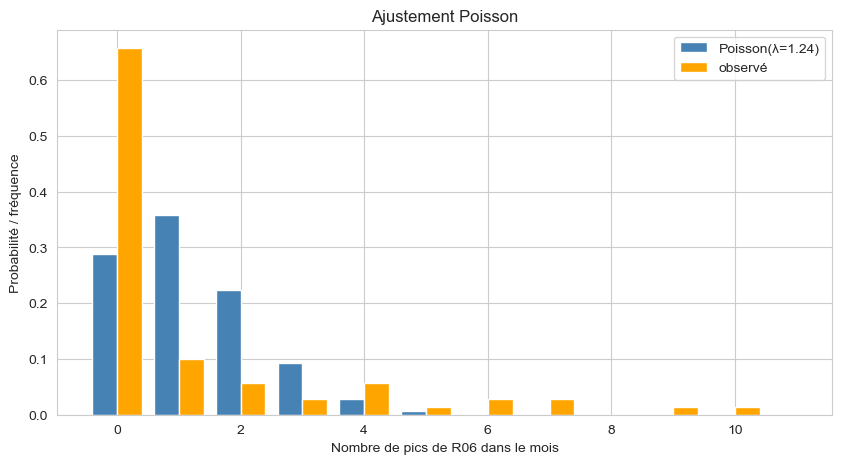

In [12]:
# Question : nombre de jours par mois où R06 dépasse un seuil élevé
seuil_R06 = df['R06'].quantile(0.95)
evt = (df['R06'] > seuil_R06).astype(int)
par_mois = evt.resample('ME').sum()

moyenne = par_mois.mean()
variance = par_mois.var(ddof=1)
print(f'λ (moyenne)    = {moyenne:.2f}')
print(f'variance       = {variance:.2f}')
print(f'ratio var/moy  = {variance/moyenne:.2f}  (Poisson : ratio ~ 1)')

# Comparaison PMF observée vs PMF Poisson
k = np.arange(0, par_mois.max() + 2)
pmf_th = stats.poisson.pmf(k, moyenne)
obs = par_mois.value_counts(normalize=True).sort_index()

fig, ax = plt.subplots()
ax.bar(k - 0.2, pmf_th, width=0.4, label=f'Poisson(λ={moyenne:.2f})', color='steelblue')
ax.bar(obs.index + 0.2, obs.values, width=0.4, label='observé', color='orange')
ax.set_xlabel('Nombre de pics de R06 dans le mois')
ax.set_ylabel('Probabilité / fréquence')
ax.set_title('Ajustement Poisson')
ax.legend(); plt.show()

**Interprétation :** si le ratio variance/moyenne est proche de 1, l'événement « pic de R06 » est bien Poisson. Sinon (ratio nettement > 1), on a une **surdispersion** — souvent due à la saisonnalité (pics groupés au printemps). Pour un modèle plus juste, on stratifierait par saison.

### 5.4 Loi géométrique (mention)

Nombre d'essais avant le **premier** succès :
$$\mathbb{P}(X = k) = (1 - p)^{k-1}\,p, \quad k = 1, 2, 3, \dots$$
$$\mathbb{E}[X] = \frac{1}{p}, \qquad \mathrm{Var}(X) = \frac{1 - p}{p^2}$$

Cas pharma : nombre de visites avant la première prescription, délai en jours avant le premier pic d'une catégorie, etc.

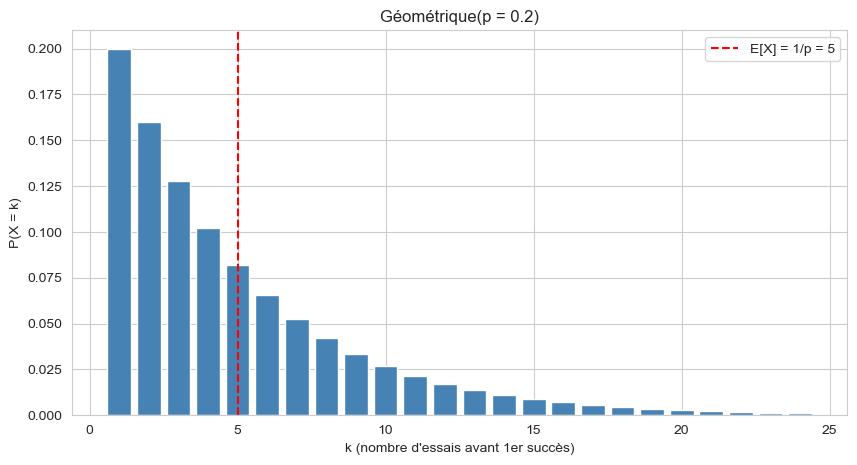

In [13]:
# Loi géométrique : exemple jouet
p = 0.2  # 20 % de succès par essai
k = np.arange(1, 25)
pmf = stats.geom.pmf(k, p)

fig, ax = plt.subplots()
ax.bar(k, pmf, color='steelblue')
ax.axvline(1/p, color='red', ls='--', label=f'E[X] = 1/p = {1/p:.0f}')
ax.set_xlabel('k (nombre d\'essais avant 1er succès)')
ax.set_ylabel('P(X = k)')
ax.set_title(f'Géométrique(p = {p})')
ax.legend(); plt.show()

### 5.5 Loi uniforme continue $U(a, b)$

$$f(x) = \frac{1}{b - a}, \quad x \in [a, b]$$
$$\mathbb{E}[X] = \frac{a+b}{2}, \qquad \mathrm{Var}(X) = \frac{(b-a)^2}{12}$$

Cas le plus simple, sert souvent de **baseline** dans les simulations.

### 5.6 Loi normale $\mathcal{N}(\mu, \sigma^2)$

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\,\exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$
$$\mathbb{E}[X] = \mu, \qquad \mathrm{Var}(X) = \sigma^2$$

**Règle 68-95-99,7 :**
$$\mathbb{P}(|X-\mu| \leq \sigma) \approx 68\,\%, \quad \mathbb{P}(|X-\mu| \leq 2\sigma) \approx 95\,\%, \quad \mathbb{P}(|X-\mu| \leq 3\sigma) \approx 99{,}7\,\%$$

Vérifions sur des tirages.

In [14]:
echantillon = stats.norm.rvs(loc=0, scale=1, size=100_000, random_state=42)
for k in [1, 2, 3]:
    proportion = ((echantillon >= -k) & (echantillon <= k)).mean()
    print(f'P(|X| <= {k}σ) observé = {proportion:.3%}')

P(|X| <= 1σ) observé = 68.159%
P(|X| <= 2σ) observé = 95.447%
P(|X| <= 3σ) observé = 99.736%


### 5.7 Loi log-normale — ajustement empirique sur R06

$$\ln(X) \sim \mathcal{N}(\mu, \sigma^2)$$

Pour vérifier qu'une variable est log-normale, on regarde si **$\ln(X)$ est normale**. Méthode : QQ-plot.

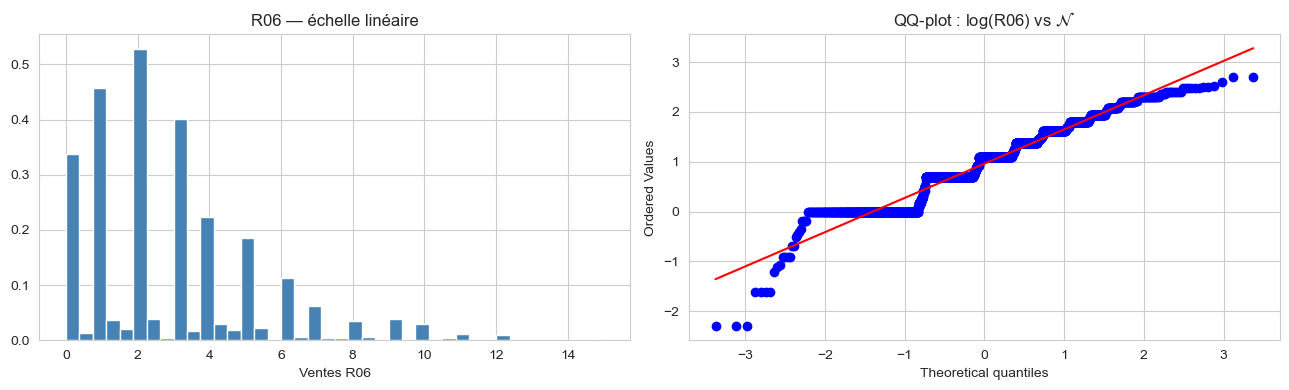

log(R06) — moyenne = 0.96, écart-type = 0.70
Skewness log(R06) = -0.25  (proche de 0 si gaussien)


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogramme de R06 + log(R06)
log_R06 = np.log(df['R06'].replace(0, np.nan).dropna())
axes[0].hist(df['R06'], bins=40, density=True, color='steelblue', edgecolor='white')
axes[0].set_title('R06 — échelle linéaire')
axes[0].set_xlabel('Ventes R06')

# QQ-plot vs normale
stats.probplot(log_R06, dist='norm', plot=axes[1])
axes[1].set_title('QQ-plot : log(R06) vs $\\mathcal{N}$')
plt.tight_layout(); plt.show()

# Statistiques de log(R06)
print(f'log(R06) — moyenne = {log_R06.mean():.2f}, écart-type = {log_R06.std():.2f}')
print(f'Skewness log(R06) = {log_R06.skew():.2f}  (proche de 0 si gaussien)')

**Lecture :** si les points du QQ-plot sont alignés sur la diagonale, $\log(R06)$ est gaussien $\Rightarrow$ R06 est **log-normale**. La skewness de $\log(R06)$ proche de 0 confirme la même chose.

**Conséquence pratique :** pour modéliser ou simuler des ventes R06, mieux vaut travailler **en log** — les hypothèses de normalité y sont vérifiées.

### 5.8 Loi exponentielle $\mathrm{Exp}(\lambda)$

$$f(x) = \lambda\,e^{-\lambda x}, \quad x \geq 0$$
$$\mathbb{E}[X] = \frac{1}{\lambda}, \qquad \mathrm{Var}(X) = \frac{1}{\lambda^2}$$

Modélise les **durées entre événements**. Lien avec Poisson : si les événements arrivent selon Poisson($\lambda$), les durées entre événements sont Exp($\lambda$).

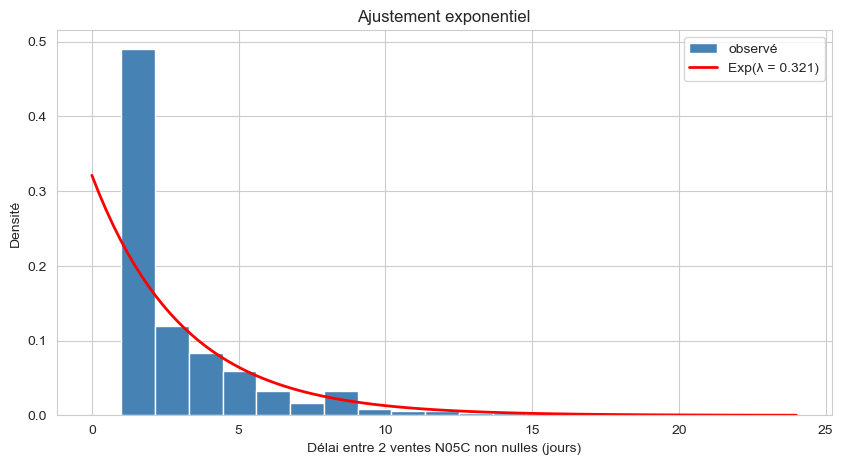

In [16]:
# Durées entre deux ventes non nulles de N05C (catégorie où les zéros sont fréquents)
non_zero = df.index[df['N05C'] > 0]
delais = np.diff(non_zero).astype('timedelta64[D]').astype(int)
delais = delais[delais > 0]   # on ne garde que les délais positifs

lam_est = 1 / delais.mean()  # estimation de lambda
x = np.linspace(0, delais.max(), 100)

fig, ax = plt.subplots()
ax.hist(delais, bins=20, density=True, color='steelblue', edgecolor='white',
        label='observé')
ax.plot(x, stats.expon.pdf(x, scale=1/lam_est), color='red', lw=2,
        label=f'Exp(λ = {lam_est:.3f})')
ax.set_xlabel('Délai entre 2 ventes N05C non nulles (jours)')
ax.set_ylabel('Densité')
ax.set_title('Ajustement exponentiel')
ax.legend(); plt.show()

**Interprétation :** si la courbe rouge colle à l'histogramme, les délais entre ventes N05C suivent bien une exponentielle $\Rightarrow$ les ventes elles-mêmes sont un processus **Poissonien**. Utile pour dimensionner les stocks et anticiper les délais entre commandes.

### 5.9 Lois des tests (Student, $\chi^2$, Fisher)

Trois lois que vous croiserez en Module 8. Pas besoin de les calculer — juste les **reconnaître** dans les sorties d'un test.

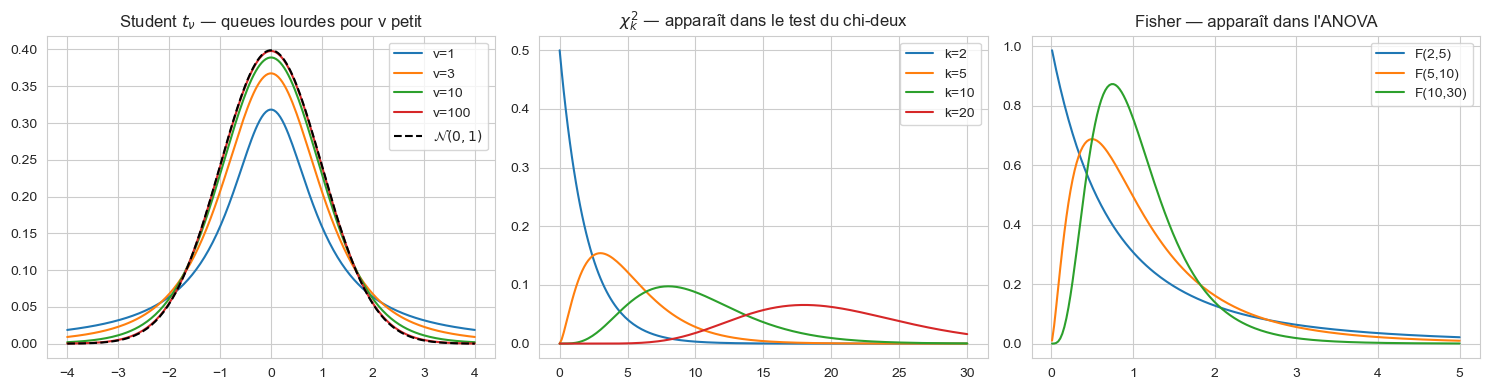

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Student
x = np.linspace(-4, 4, 200)
for nu in [1, 3, 10, 100]:
    axes[0].plot(x, stats.t.pdf(x, nu), label=f'ν={nu}')
axes[0].plot(x, stats.norm.pdf(x), 'k--', label='$\\mathcal{N}(0,1)$')
axes[0].set_title('Student $t_\\nu$ — queues lourdes pour ν petit')
axes[0].legend()

# Chi²
x = np.linspace(0, 30, 200)
for k_ in [2, 5, 10, 20]:
    axes[1].plot(x, stats.chi2.pdf(x, k_), label=f'k={k_}')
axes[1].set_title('$\\chi^2_k$ — apparaît dans le test du chi-deux')
axes[1].legend()

# Fisher
x = np.linspace(0.01, 5, 200)
for d1, d2 in [(2, 5), (5, 10), (10, 30)]:
    axes[2].plot(x, stats.f.pdf(x, d1, d2), label=f'F({d1},{d2})')
axes[2].set_title('Fisher — apparaît dans l\'ANOVA')
axes[2].legend()
plt.tight_layout(); plt.show()

**À retenir :** la p-value renvoyée par un test correspond à un **quantile** de l'une de ces lois. Dans `scipy.stats`, on utilise `.cdf` ou `.sf` pour faire le calcul soi-même.

### 5.10 Odds et odds ratio

$$\mathrm{Odds}(A) = \frac{\mathbb{P}(A)}{1 - \mathbb{P}(A)}, \qquad \mathrm{OR} = \frac{\mathrm{Odds}(A \mid \text{cond. 1})}{\mathrm{Odds}(A \mid \text{cond. 2})}$$

**Lecture :**
- $\mathrm{OR} > 1$ : la condition 1 augmente les chances de $A$.
- $\mathrm{OR} = 1$ : pas d'effet.
- $\mathrm{OR} < 1$ : la condition 1 réduit les chances de $A$.

Utile pour la régression logistique (Module 10).

In [18]:
# Question : la probabilité d'une 'forte vente N02BE' est-elle modifiée le week-end ?
forte = df['N02BE'] > df['N02BE'].quantile(0.75)
weekend = df.index.dayofweek >= 5

p_we    = forte[weekend].mean()
p_sem   = forte[~weekend].mean()
odds_we  = p_we / (1 - p_we)
odds_sem = p_sem / (1 - p_sem)
OR = odds_we / odds_sem

print(f'P(forte | week-end)  = {p_we:.3f}    odds = {odds_we:.3f}')
print(f'P(forte | semaine)   = {p_sem:.3f}    odds = {odds_sem:.3f}')
print(f'OR (week-end vs semaine) = {OR:.3f}')

P(forte | week-end)  = 0.331    odds = 0.494
P(forte | semaine)   = 0.217    odds = 0.278
OR (week-end vs semaine) = 1.777


**Interprétation :**
- $\mathrm{OR} \ll 1$ : être en week-end **divise** les odds de forte vente.
- L'OR est l'unité naturelle de la régression logistique : le coefficient $\beta$ d'une variable se lit en `exp(β) = OR`.

**Piège pédagogique :** ne jamais présenter un OR à un public business sans le traduire en probabilité. « OR = 0,3 » n'est pas la même chose que « 30 % de chances ».

### 5.11 `scipy.stats` — cheatsheet

| Méthode | Calcule | Cas d'usage |
|---|---|---|
| `.pdf(x)` / `.pmf(k)` | densité / proba ponctuelle | tracer la loi |
| `.cdf(x)` | $\mathbb{P}(X \leq x)$ | proba cumulée |
| `.sf(x)` | $\mathbb{P}(X > x) = 1 - \mathrm{cdf}$ | p-value côté droit |
| `.ppf(q)` | quantile d'ordre $q$ | seuil P95, P99 |
| `.rvs(n)` | $n$ tirages aléatoires | simulation, bootstrap |
| `.fit(data)` | estimation des paramètres | ajustement empirique |

In [19]:
# Démonstration croisée sur la normale standard
loi = stats.norm(0, 1)
x0 = 1.96

print(f'pdf(1.96)        = {loi.pdf(x0):.4f}     (densité, pas une proba)')
print(f'cdf(1.96)        = {loi.cdf(x0):.4f}     (proba P(X <= 1.96))')
print(f'sf(1.96)         = {loi.sf(x0):.4f}     (proba P(X > 1.96))')
print(f'ppf(0.975)       = {loi.ppf(0.975):.4f} (seuil tel que P(X <= seuil) = 0.975)')
print(f'rvs(5)           = {loi.rvs(5, random_state=42).round(2)}')

pdf(1.96)        = 0.0584     (densité, pas une proba)
cdf(1.96)        = 0.9750     (proba P(X <= 1.96))
sf(1.96)         = 0.0250     (proba P(X > 1.96))
ppf(0.975)       = 1.9600 (seuil tel que P(X <= seuil) = 0.975)
rvs(5)           = [ 0.5  -0.14  0.65  1.52 -0.23]


**Remarque :** $\mathrm{ppf}(0{,}975) = 1{,}96$. C'est le seuil du fameux IC à 95 % — on le retrouvera en Module 6.

### 5.12 Cas pratique — méthode d'ajustement empirique

Pour vérifier qu'une variable suit une loi connue :
1. **Hypothèse visuelle** : histogramme + KDE. Quelle forme ?
2. **Estimation** : `loi.fit(data)`.
3. **Vérification** : QQ-plot ou tests (Kolmogorov-Smirnov, Shapiro-Wilk).

Appliquons à N02BE pour tester la normalité.

Ajustement N(μ, σ²) : μ = 29.92, σ = 15.59
Test Kolmogorov-Smirnov : p-value = 8.339e-15


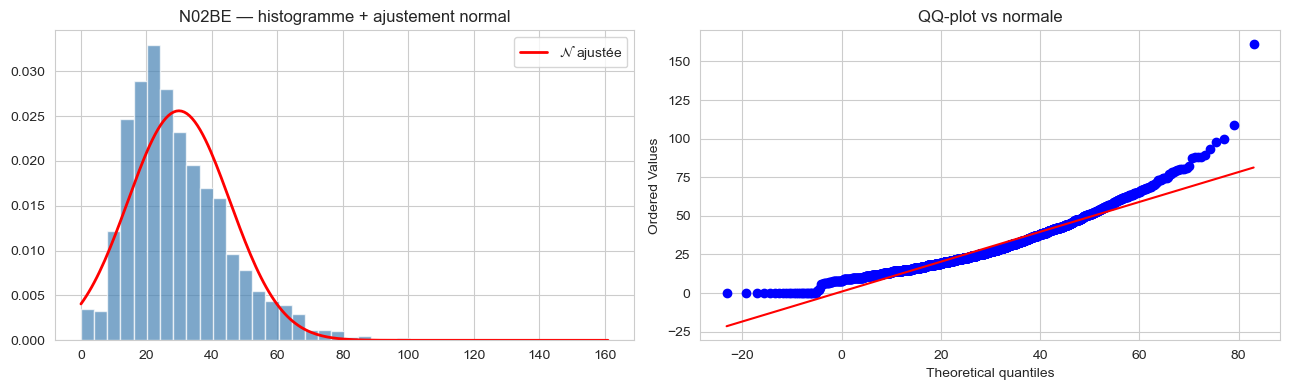

In [20]:
x = df['N02BE'].values

# Étape 1-2 : ajuster une normale
mu, sigma = stats.norm.fit(x)
print(f'Ajustement N(μ, σ²) : μ = {mu:.2f}, σ = {sigma:.2f}')

# Étape 3 : tester la normalité
ks_stat, ks_p = stats.kstest(x, 'norm', args=(mu, sigma))
print(f'Test Kolmogorov-Smirnov : p-value = {ks_p:.4g}')

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
xx = np.linspace(x.min(), x.max(), 200)
axes[0].hist(x, bins=40, density=True, color='steelblue', edgecolor='white', alpha=0.7)
axes[0].plot(xx, stats.norm.pdf(xx, mu, sigma), 'r-', lw=2, label='$\\mathcal{N}$ ajustée')
axes[0].set_title('N02BE — histogramme + ajustement normal')
axes[0].legend()

stats.probplot(x, dist='norm', sparams=(mu, sigma), plot=axes[1])
axes[1].set_title('QQ-plot vs normale')
plt.tight_layout(); plt.show()

**Lecture :** si la p-value du test KS est très petite, on **rejette** la normalité — c'est typiquement le cas sur N02BE à cause de l'effet jour de la semaine et de la saisonnalité. Dans ce cas, deux options pédagogiques :
- Travailler en sous-groupes (par jour de la semaine) où l'hypothèse devient plus défendable.
- Utiliser des tests **non paramétriques** (Module 8) qui ne supposent pas la normalité.

### 5.13 Pièges courants — Module 5

1. **Forcer la normalité partout** — beaucoup de phénomènes business sont log-normaux ou Poissoniens.
2. Confondre **loi théorique** et **distribution empirique**.
3. Appliquer Poisson sur des données **surdispersées** ($s^2 \gg \bar{x}$).
4. Lire la densité $f(x)$ comme une probabilité.
5. Confondre **odds** et **probabilité** dans une présentation business.

---
## Synthèse de la Partie 2

À l'issue de ce TP, vous savez :

- Manipuler le vocabulaire probabiliste : événement, variable aléatoire, loi, espérance, variance.
- Calculer une probabilité conditionnelle, vérifier l'indépendance, appliquer Bayes.
- Distinguer PMF, PDF, CDF — savoir laquelle utiliser pour quel calcul.
- Reconnaître les lois usuelles (Bernoulli, binomiale, Poisson, géométrique, uniforme, normale, log-normale, exponentielle).
- Calculer et interpréter une **odds ratio**.
- Manipuler une loi avec `scipy.stats` : `pdf`, `cdf`, `ppf`, `rvs`, `fit`.
- Mener un ajustement empirique (visualisation $\to$ estimation $\to$ test).

### Cheatsheet — formules essentielles

| Concept | Formule |
|---|---|
| Probabilité conditionnelle | $\mathbb{P}(A \mid B) = \mathbb{P}(A \cap B)/\mathbb{P}(B)$ |
| Indépendance | $\mathbb{P}(A \cap B) = \mathbb{P}(A)\mathbb{P}(B)$ |
| Bayes | $\mathbb{P}(A \mid B) = \mathbb{P}(B \mid A)\mathbb{P}(A) / \mathbb{P}(B)$ |
| Espérance | $\mathbb{E}[X] = \sum k\, p_X(k)$ ou $\int x\, f_X(x) \mathrm{d}x$ |
| Variance | $\mathrm{Var}(X) = \mathbb{E}[(X - \mu)^2] = \mathbb{E}[X^2] - \mu^2$ |
| Bernoulli | $\mathbb{E} = p$, $\mathrm{Var} = p(1-p)$ |
| Binomiale | $\binom{n}{k} p^k (1-p)^{n-k}$, $\mathbb{E} = np$ |
| Poisson | $\lambda^k e^{-\lambda}/k!$, $\mathbb{E} = \mathrm{Var} = \lambda$ |
| Normale | $f(x) = \frac{1}{\sigma\sqrt{2\pi}} e^{-(x-\mu)^2/(2\sigma^2)}$ |
| Log-normale | $\ln(X) \sim \mathcal{N}$ |
| Exponentielle | $\lambda e^{-\lambda x}$, $\mathbb{E} = 1/\lambda$ |
| Odds | $\mathbb{P}/(1 - \mathbb{P})$ |
| Odds ratio | $\mathrm{OR} = \exp(\beta)$ en régression logistique |

### Suite

Le prochain TP couvrira la **Partie 3 — Statistiques inférentielles** (Modules 6 à 10) :
- Module 6 : TCL, intervalles de confiance.
- Module 7 : tests d'hypothèses, p-value.
- Module 8 : choisir le bon test.
- Module 9 : régression linéaire.
- Module 10 : régression logistique (avec les odds vus ici).